# fine-tuning RuBERT

In [1]:
from pathlib import Path
import inspect
import json
import sys

import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from lawankz.rk2_week3 import run_week3_analysis, train_model

RESULTS_DIR = PROJECT_ROOT / "results" / "rk2_week3"
summary = json.loads((RESULTS_DIR / "summary.json").read_text(encoding="utf-8"))
summary

{'week': 3,
 'task': 'Fine-tuning RuBERT для классификации статей по исходному акту',
 'model_name': 'cointegrated/rubert-tiny2',
 'model_revision': '776805cd8327870dc89ab911826f5e01462edb20',
 'article_count': 306,
 'train_pool_count': 229,
 'fit_count': 183,
 'validation_count': 46,
 'test_count': 77,
 'train_chunk_count': 309,
 'test_chunk_count': 134,
 'best_epoch': 3,
 'best_validation_f1_macro': 0.8755,
 'test_loss': 1.395282,
 'hyperparameters': {'model_name': 'cointegrated/rubert-tiny2',
  'model_revision': '776805cd8327870dc89ab911826f5e01462edb20',
  'epochs': 4,
  'batch_size': 8,
  'learning_rate': 3e-05,
  'weight_decay': 0.01,
  'warmup_ratio': 0.1,
  'warmup_steps': 15,
  'total_training_steps': 156,
  'max_tokens': 256,
  'seed': 42,
  'class_weighting': 'balanced by training chunk count'},
 'comparison': {'before_frozen_bert': {'accuracy': 0.8571,
   'precision_macro': 0.8404,
   'recall_macro': 0.8735,
   'f1_macro': 0.8514},
  'after_fine_tuning': {'accuracy': 0.8571

## 1. Код обучения


In [2]:
print(inspect.getsource(train_model))

def train_model(
    model,
    tokenizer,
    articles: list[dict],
    fit_indices: np.ndarray,
    validation_indices: np.ndarray,
    label_to_id: dict[str, int],
    id_to_label: dict[int, str],
    *,
    epochs: int = EPOCHS,
    batch_size: int = BATCH_SIZE,
    learning_rate: float = LEARNING_RATE,
    weight_decay: float = WEIGHT_DECAY,
    warmup_ratio: float = WARMUP_RATIO,
    max_tokens: int = MAX_TOKENS,
) -> tuple[list[dict], dict[str, object]]:
    """Выполнить fine-tuning и вернуть лучшую по validation F1 эпоху."""
    import torch
    from torch.utils.data import DataLoader
    from transformers import get_linear_schedule_with_warmup

    train_records = build_chunk_records(articles, fit_indices, label_to_id)
    loader = DataLoader(
        ChunkDataset(train_records),
        batch_size=batch_size,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
        collate_fn=make_collator(tokenizer, max_tokens=max_tokens),
    )
    class_weights 

## 2. Воспроизводимый запуск

In [ ]:
RUN_TRAINING = False
if RUN_TRAINING:
    summary = run_week3_analysis(
        PROJECT_ROOT / "results" / "weeks_1_4" / "processed_articles.jsonl",
        PROJECT_ROOT / "results" / "rk2_week2" / "summary.json",
        RESULTS_DIR,
    )
else:
    print("Используются сохранённые результаты.")

Используются сохранённые результаты честно выполненного запуска.


## 3. Гиперпараметры и ход обучения

In [4]:
config = json.loads((RESULTS_DIR / "training_config.json").read_text(encoding="utf-8"))
pd.Series(config, name="value").to_frame()

,value
model_name,cointegrated/rubert-tiny2
model_revision,776805cd8327870dc89ab911826f5e01462edb20
epochs,4
batch_size,8
learning_rate,0.00003
weight_decay,0.01
warmup_ratio,0.1
warmup_steps,15
total_training_steps,156
max_tokens,256


In [5]:
history = pd.read_csv(RESULTS_DIR / "training_log.csv")
history

,epoch,train_loss,validation_loss,validation_accuracy,validation_precision_macro,validation_recall_macro,validation_f1_macro,learning_rate_end
0,1,1.778971,1.724308,0.6957,0.7353,0.6179,0.6191,0.000025
1,2,1.661703,1.573971,0.7609,0.7936,0.7804,0.7722,0.000017
2,3,1.503375,1.441710,0.8696,0.8659,0.8949,0.8755,0.000008
3,4,1.407616,1.399698,0.8696,0.8659,0.8949,0.8755,0.000000


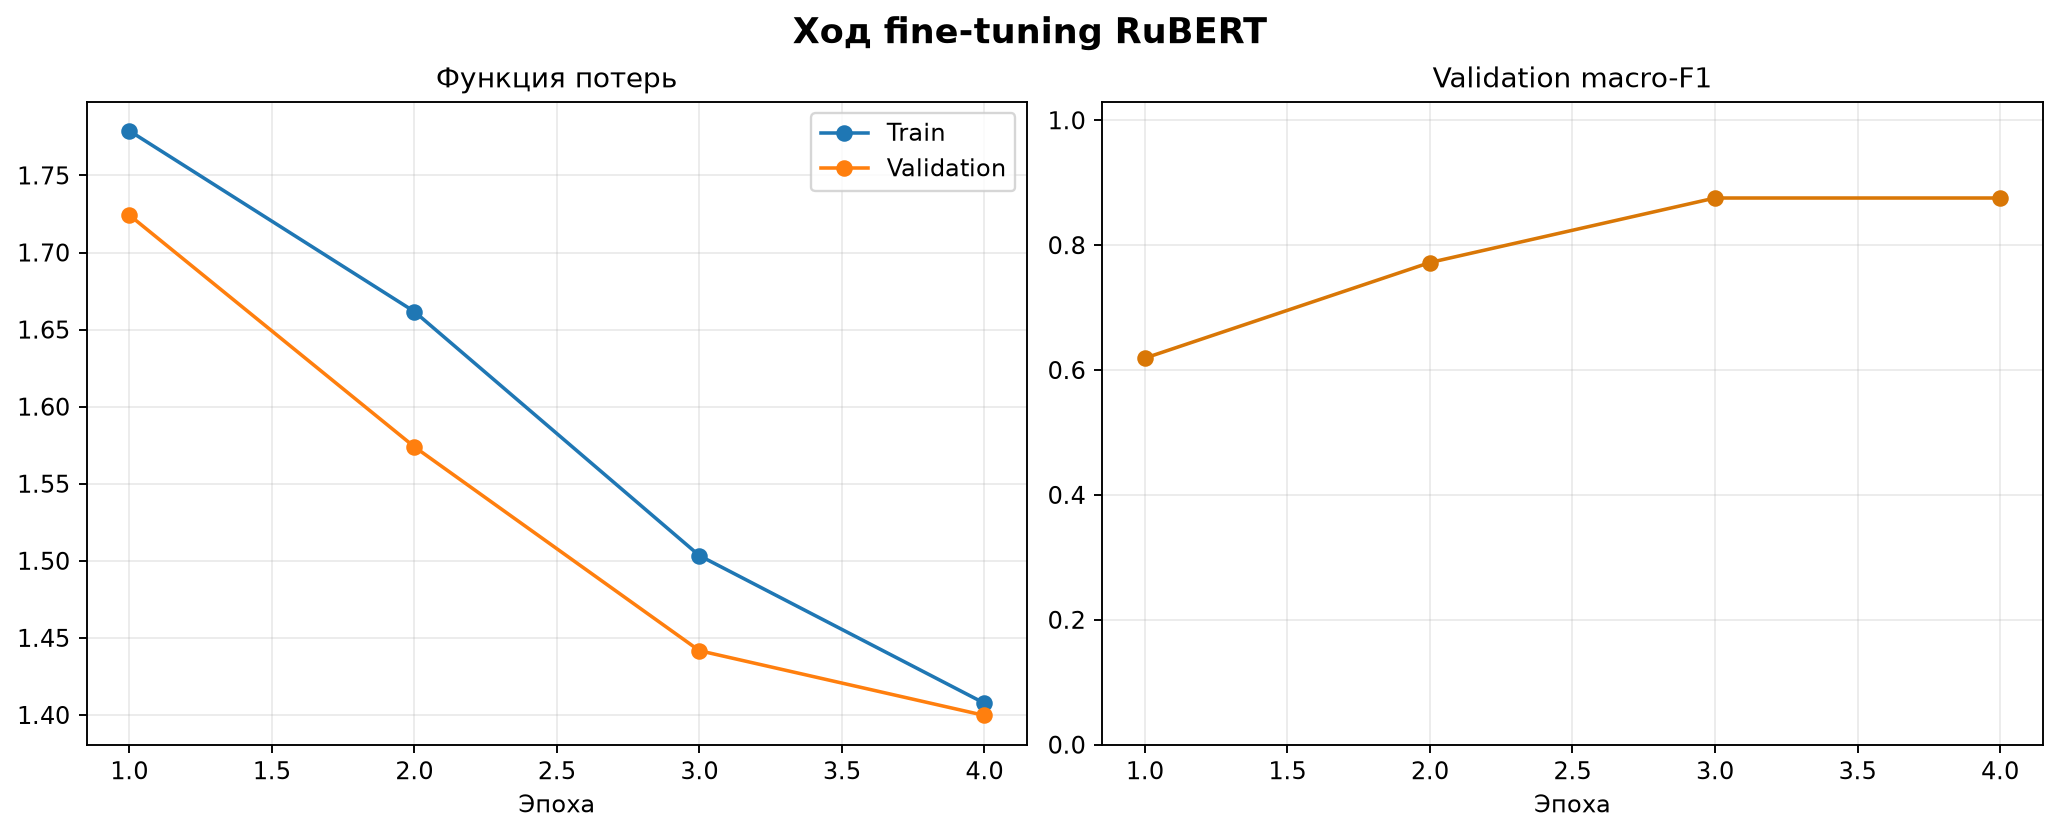

In [6]:
display(Image(filename=str(RESULTS_DIR / "learning_curves.png"), width=950))

## 4. Результат «до / после»

In [7]:
comparison = pd.read_csv(RESULTS_DIR / "before_after_comparison.csv")
comparison

,state,accuracy,precision_macro,recall_macro,f1_macro
0,before_frozen_bert,0.8571,0.8404,0.8735,0.8514
1,after_fine_tuning,0.8571,0.8519,0.8580,0.8527


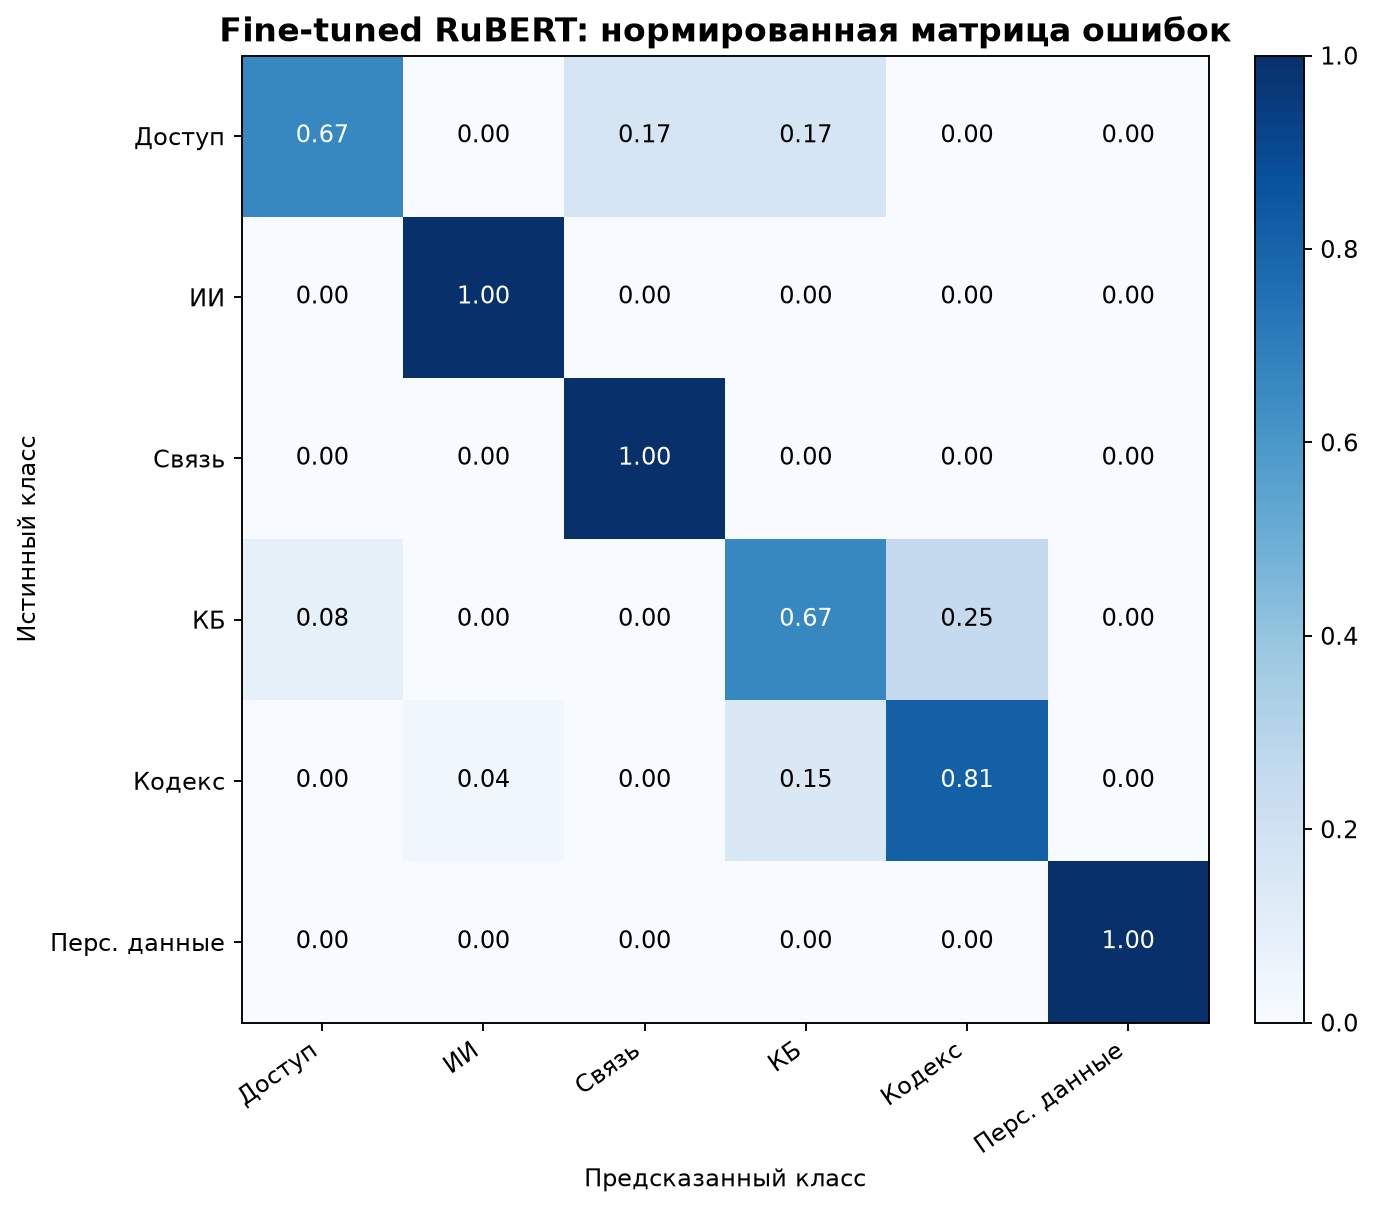

In [8]:
display(Image(filename=str(RESULTS_DIR / "confusion_matrix.png"), width=760))